### 과제명: 여행 소비 고지출자 예측 서비스 구현 (시·도 선호지역 정보 추가)
(Streamlit + FastAPI 연동)

#### 과제 설명
기존 여행 소비 고지출자 예측 프로젝트에 TRAVEL_LIKE_SIDO_1 + TRAVEL_LIKE_SGG_1 컬럼을 추가하여,
데이터 전처리 → 모델 학습 → 예측 UI 도구 제작까지의 전체 과정을 수행하세요.

사용 데이터셋
- 제공된 CSV 파일 **tn_traveller_master_with_total_top20.csv**를 사용하세요.
- 타깃 컬럼은 **top20_spender**입니다.

수행 단계
1. TRAVEL_LIKE_SIDO_1 + TRAVEL_LIKE_SGG_1 컬럼을 포함하여 데이터 전처리를 수행하세요.

2. 범주형 변수에 대해 One-Hot Encoding을 적용하세요.

3. 데이터를 Train / Validation / Test로 분리하세요.

4. 수치형 변수에 대해 StandardScaler를 적용하세요.

5. 로지스틱 회귀 모델을 학습하고 저장하세요.

6. FastAPI 기반 예측 API를 구현하세요.

7. Streamlit 기반 UI를 구성하여 예측 결과를 확인할 수 있도록 하세요.

결과 요구사항
- UI 화면에 다음 정보를 출력하세요.
- 고지출자 예측 결과(label)
- 고지출자 예측 확률(probability)
- 기존 선택 사항들 + TRAVEL_LIKE_SIDO_1 선택 박스 + TRAVEL_LIKE_SGG_1 선택 박스

제출 자료 
- 아래 파일을 하나의 폴더로 구성한 후 ZIP 파일로 압축하여 제출하세요.
- 파일명: 이름_프로젝트.zip
- 필수 포함 파일
- train.py 또는 train.ipynb : 전처리 및 모델 학습
- server.py : FastAPI 예측 서버
- app.py : Streamlit UI

 



### 1. TRAVEL_LIKE_SIDO_1 + TRAVEL_LIKE_SGG_1 컬럼을 포함하여 데이터 전처리를 수행하세요.

In [2]:
# 1. 데이터 셋 불러오기
# 구조 확인
# 상위 5개 행 확인

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt


CSV_PATH = "tn_traveller_master_with_total_top20.csv"
TARGET = "top_spender"

RANDOM_STATE = 42
TEST_SIZE = 0.2
VALID_SIZE = 0.2

df_org = pd.read_csv(CSV_PATH)

print('1단계 - 원본 데이터 크기(shape):', df_org.shape)
df_org.head()

df = df_org.copy()



1단계 - 원본 데이터 크기(shape): (3200, 27)


In [3]:
if "TRAVEL_STATUS_YMD" in df.columns:
    date_parts = df["TRAVEL_STATUS_YMD"].str.split("~", n=1, expand=True)
    start = pd.to_datetime(date_parts[0].str.strip(), errors="coerce")
    end = pd.to_datetime(date_parts[1].str.strip(), errors="coerce")
    df["TRIP_DAYS"] = (end - start).dt.days + 1

print(f'TRIP_DAYS 생성 완료 {df["TRIP_DAYS"].count()}개')

TRIP_DAYS 생성 완료 3200개


In [4]:
# 지역명 통일
df["TRAVEL_STATUS_RESIDENCE"]
region_map = {
    '서울특별시':'서울', '부산광역시':'부산', '대구광역시':'대구',
    '인천광역시':'인천', '광주광역시':'광주', '대전광역시':'대전',
    '울산광역시':'울산', '세종특별자치시':'세종', '경기도':'경기',
    '강원도':'강원', '강원특별자치도':'강원', '충청북도':'충북',
    '충청남도':'충남', '전라북도':'전북', '전북특별자치도':'전북',
    '전라남도':'전남', '경상북도':'경북', '경상남도':'경남',
    '제주특별자치도':'제주'
}
for col in ['TRAVEL_STATUS_RESIDENCE', 'TRAVEL_STATUS_DESTINATION']:
    if col in df.columns:
        # 변경 전 값 저장
        # before = df[col].copy()

        # 지역명 변경
        df[col] = df[col].replace(region_map)

#TRAVEL_LIKE_SIDO_1 + TRAVEL_LIKE_SGG_1 유지
# 드랍할 컬럼
DROP_COLS = [
    "TRAVELER_ID",
    "RESIDENCE_SGG_CD",
    "TRAVEL_STATUS_YMD",
    "total_spend"
]

drop_cols_exist = [c for c in DROP_COLS if c in df.columns]
df = df.drop(columns=drop_cols_exist)
print("드랍한 컬럼: ", drop_cols_exist)
print("드랍 후 데이터 크기: ", df.shape)

드랍한 컬럼:  ['TRAVELER_ID', 'RESIDENCE_SGG_CD', 'TRAVEL_STATUS_YMD', 'total_spend']
드랍 후 데이터 크기:  (3200, 24)


In [5]:
# 결측치 확인
missing_before = pd.DataFrame({
    '결측치 수': df.isna().sum(),
    '결측 비율(%)': df.isna().mean().mul(100)
}).query('`결측치 수` > 0').sort_values('결측 비율(%)', ascending=False)
missing_before.round(2)

,결측치 수,결측 비율(%)
JOB_ETC,3059,95.59
HOUSE_INCOME,844,26.38
TRAVEL_MOTIVE_3,251,7.84
JOB_NM,141,4.41
TRAVEL_MOTIVE_2,123,3.84
MARR_STTS,2,0.06
EDU_FNSH_SE,1,0.03


In [6]:
#결측치가 대부분인 JOB_ETC 제거
df_clean = df.drop(columns=['JOB_ETC']).copy()

# 범주형은 결측치에 최빈값으로 대체
category_cols = ['TRAVEL_MOTIVE_3', 'JOB_NM', 'TRAVEL_MOTIVE_2', 'MARR_STTS', 'EDU_FNSH_SE']
for col in category_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode().iloc[0])

# 수치형은 평균으로 하면 이상치 때문에 데이터가 신뢰하기 어려워 중앙값으로 대체
df_clean['HOUSE_INCOME'] = df_clean['HOUSE_INCOME'].fillna(df_clean['HOUSE_INCOME'].median())

# print('처리 후 결측치:', df_clean.isna().sum())
print('처리 후 전체 결측치 수:', df_clean.isna().sum().sum())


처리 후 전체 결측치 수: 0


In [7]:
df_clean[["TRAVEL_LIKE_SIDO_1", "TRAVEL_LIKE_SGG_1"]]

,TRAVEL_LIKE_SIDO_1,TRAVEL_LIKE_SGG_1
0,50,50110
1,41,41460
2,50,50130
3,42,42830
4,42,42210
...,...,...
3195,42,42150
3196,46,46710
3197,48,48310
3198,41,41450


In [8]:
print(f"시도 {df_clean['TRAVEL_LIKE_SIDO_1'].nunique()}개", df_clean['TRAVEL_LIKE_SIDO_1'].value_counts())
print(f"시군구 {df_clean['TRAVEL_LIKE_SGG_1'].nunique()}개", df_clean['TRAVEL_LIKE_SGG_1'].value_counts())

시도 16개 TRAVEL_LIKE_SIDO_1
42    868
50    845
41    481
11    429
26    205
28     67
47     67
46     66
48     46
44     38
45     29
43     20
30     13
27     13
29      9
31      4
Name: count, dtype: int64
시군구 176개 TRAVEL_LIKE_SGG_1
50130    486
50110    359
42150    358
42210    243
26350    130
        ... 
11380      1
11545      1
28245      1
47190      1
46770      1
Name: count, Length: 176, dtype: int64


In [9]:
# 원-핫 인코딩할 컬럼 (범주형 컬럼 숫자의 크기는 의미 없음)
# TRAVEL_LIKE_SIDO_1, TRAVEL_LIKE_SGG_1도 범주형
ONE_COLS = [
    "GENDER",
    "JOB_NM",
    "TRAVEL_MOTIVE_1",
    "MARR_STTS",
    "TRAVEL_STATUS_RESIDENCE",
    "TRAVEL_STATUS_DESTINATION",
    "TRAVEL_STATUS_ACCOMPANY",
    "TRAVEL_LIKE_SIDO_1",
    "TRAVEL_LIKE_SGG_1"
]
df_encoded = pd.get_dummies(
    df_clean, columns=ONE_COLS, drop_first=True, dtype=int
)

assert not df_encoded.columns.duplicated().any(), '중복 컬럼명이 있습니다.'
missing = df_encoded.isna().sum()
print(missing[missing > 0])
assert int(df_encoded.isna().sum().sum()) == 0, '인코딩 후 결측치가 남아 있습니다.'
print('3단계 - One-Hot Encoding 후 데이터 크기(shape):', df_encoded.shape)

Series([], dtype: int64)
3단계 - One-Hot Encoding 후 데이터 크기(shape): (3200, 265)


In [10]:
# 입력변수와 타겟 변수 분리

target_col = 'top20_spender'
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col].astype(int)

# 타깃변수 고유값 확인
print('타깃 고유값:', y.unique())

# 타깃변수 결측치 확인
print('타깃 결측치 수:', y.isna().sum())

assert set(y.unique()).issubset({0, 1}), '타깃은 0과 1로 구성되어야 합니다.'
print('입력 변수 X:', X.shape)
print('타깃 y:', y.shape)

타깃 고유값: [0 1]
타깃 결측치 수: 0
입력 변수 X: (3200, 264)
타깃 y: (3200,)


In [11]:
# Train / Validation / Test 데이터셋 분리
# Test: 전체의 20%, Validation: 나머지 80% 중 20%
RANDOM_STATE = 42
TEST_SIZE = 0.2
VALID_SIZE = 0.2

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=VALID_SIZE, random_state=RANDOM_STATE, stratify=y_temp
)

print('Train 데이터 크기:', X_train.shape, y_train.shape)
print('Validation 데이터 크기:', X_valid.shape, y_valid.shape)
print('Test 데이터 크기:', X_test.shape, y_test.shape)
print('타깃 비율 - Train/Valid/Test:',
      round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Train 데이터 크기: (2048, 264) (2048,)
Validation 데이터 크기: (512, 264) (512,)
Test 데이터 크기: (640, 264) (640,)
타깃 비율 - Train/Valid/Test: 0.1982 0.1992 0.1984


In [12]:
# 수치형 변수 StandardScaler로 스케일링
# 원핫 더미 컬럼 제거한 스케일링 필요 컬럼
X_train.columns

# 원-핫 인코딩으로 생성된 컬럼 찾기
dummy_cols = [
    col for col in X_train.columns
    if any(col.startswith(f"{one_col}_") for one_col in ONE_COLS)
]

# 수치형 컬럼
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

# 원-핫 컬럼을 제외한 실제 스케일링 대상
scale_cols = [
    col for col in numeric_cols
    if col not in dummy_cols
]

print("전체 컬럼 수:", len(X_train.columns))
print("원-핫 컬럼 수:", len(dummy_cols))
print("스케일링 컬럼 수:", len(scale_cols))

print("\n전체:")
print(X_train.columns)
print("\n스케일링 대상:")
print(scale_cols)

scaler = StandardScaler()

float_cast = {c: 'float64' for c in scale_cols}
X_train_scaled = X_train.copy().astype(float_cast)
X_valid_scaled = X_valid.copy().astype(float_cast)
X_test_scaled = X_test.copy().astype(float_cast)
X_train_scaled.loc[:, scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_valid_scaled.loc[:, scale_cols] = scaler.transform(X_valid[scale_cols])
X_test_scaled.loc[:, scale_cols] = scaler.transform(X_test[scale_cols])

print('6단계 - 스케일링 컬럼 수:', len(scale_cols))
print('6단계 - 스케일링 적용 후 Train/Valid/Test:',
      X_train_scaled.shape, X_valid_scaled.shape, X_test_scaled.shape)

X_train_scaled.head()


전체 컬럼 수: 264
원-핫 컬럼 수: 251
스케일링 컬럼 수: 13

전체:
Index(['AGE_GRP', 'EDU_NM', 'EDU_FNSH_SE', 'FAMILY_MEMB', 'INCOME',
       'HOUSE_INCOME', 'TRAVEL_TERM', 'TRAVEL_NUM', 'TRAVEL_MOTIVE_2',
       'TRAVEL_MOTIVE_3',
       ...
       'TRAVEL_LIKE_SGG_1_48170', 'TRAVEL_LIKE_SGG_1_48220',
       'TRAVEL_LIKE_SGG_1_48240', 'TRAVEL_LIKE_SGG_1_48250',
       'TRAVEL_LIKE_SGG_1_48270', 'TRAVEL_LIKE_SGG_1_48310',
       'TRAVEL_LIKE_SGG_1_48330', 'TRAVEL_LIKE_SGG_1_48840',
       'TRAVEL_LIKE_SGG_1_50110', 'TRAVEL_LIKE_SGG_1_50130'],
      dtype='str', length=264)

스케일링 대상:
['AGE_GRP', 'EDU_NM', 'EDU_FNSH_SE', 'FAMILY_MEMB', 'INCOME', 'HOUSE_INCOME', 'TRAVEL_TERM', 'TRAVEL_NUM', 'TRAVEL_MOTIVE_2', 'TRAVEL_MOTIVE_3', 'TRAVEL_COMPANIONS_NUM', 'TRAVEL_STYLE_MODE', 'TRIP_DAYS']
6단계 - 스케일링 컬럼 수: 13
6단계 - 스케일링 적용 후 Train/Valid/Test: (2048, 264) (512, 264) (640, 264)


,AGE_GRP,EDU_NM,EDU_FNSH_SE,FAMILY_MEMB,INCOME,HOUSE_INCOME,TRAVEL_TERM,TRAVEL_NUM,TRAVEL_MOTIVE_2,TRAVEL_MOTIVE_3,TRAVEL_COMPANIONS_NUM,TRAVEL_STYLE_MODE,TRIP_DAYS,GENDER_여,JOB_NM_2.0,JOB_NM_3.0,JOB_NM_4.0,JOB_NM_5.0,JOB_NM_6.0,JOB_NM_7.0,JOB_NM_8.0,JOB_NM_9.0,JOB_NM_10.0,JOB_NM_11.0,JOB_NM_12.0,JOB_NM_13.0,TRAVEL_MOTIVE_1_2,TRAVEL_MOTIVE_1_3,TRAVEL_MOTIVE_1_4,TRAVEL_MOTIVE_1_5,TRAVEL_MOTIVE_1_6,TRAVEL_MOTIVE_1_7,TRAVEL_MOTIVE_1_8,TRAVEL_MOTIVE_1_9,TRAVEL_MOTIVE_1_10,MARR_STTS_2.0,MARR_STTS_3.0,MARR_STTS_4.0,MARR_STTS_5.0,TRAVEL_STATUS_RESIDENCE_경기,...,TRAVEL_LIKE_SGG_1_46130,TRAVEL_LIKE_SGG_1_46150,TRAVEL_LIKE_SGG_1_46170,TRAVEL_LIKE_SGG_1_46710,TRAVEL_LIKE_SGG_1_46720,TRAVEL_LIKE_SGG_1_46730,TRAVEL_LIKE_SGG_1_46770,TRAVEL_LIKE_SGG_1_46790,TRAVEL_LIKE_SGG_1_46800,TRAVEL_LIKE_SGG_1_46810,TRAVEL_LIKE_SGG_1_46820,TRAVEL_LIKE_SGG_1_46870,TRAVEL_LIKE_SGG_1_46890,TRAVEL_LIKE_SGG_1_46900,TRAVEL_LIKE_SGG_1_46910,TRAVEL_LIKE_SGG_1_47110,TRAVEL_LIKE_SGG_1_47130,TRAVEL_LIKE_SGG_1_47170,TRAVEL_LIKE_SGG_1_47190,TRAVEL_LIKE_SGG_1_47210,TRAVEL_LIKE_SGG_1_47230,TRAVEL_LIKE_SGG_1_47250,TRAVEL_LIKE_SGG_1_47280,TRAVEL_LIKE_SGG_1_47760,TRAVEL_LIKE_SGG_1_47770,TRAVEL_LIKE_SGG_1_47820,TRAVEL_LIKE_SGG_1_47830,TRAVEL_LIKE_SGG_1_47850,TRAVEL_LIKE_SGG_1_47930,TRAVEL_LIKE_SGG_1_48120,TRAVEL_LIKE_SGG_1_48170,TRAVEL_LIKE_SGG_1_48220,TRAVEL_LIKE_SGG_1_48240,TRAVEL_LIKE_SGG_1_48250,TRAVEL_LIKE_SGG_1_48270,TRAVEL_LIKE_SGG_1_48310,TRAVEL_LIKE_SGG_1_48330,TRAVEL_LIKE_SGG_1_48840,TRAVEL_LIKE_SGG_1_50110,TRAVEL_LIKE_SGG_1_50130
625,-0.040512,1.472052,-0.369675,-0.530083,0.464004,1.632446,-0.715330,-0.779895,0.660389,-0.284737,-0.193216,0.562176,-0.733456,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1982,-1.016623,2.753294,0.756953,-0.530083,-0.039056,-1.490418,0.882266,0.169421,-0.942546,-0.654985,-0.193216,1.746679,0.538448,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1185,-1.016623,0.190810,-0.369675,0.262333,0.464004,1.632446,-0.715330,0.169421,1.461856,1.566505,-0.834557,0.562176,-0.733456,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
308,-1.016623,-2.371674,-0.369675,0.262333,-0.542115,-1.936542,0.882266,0.169421,-0.541812,1.196257,-0.834557,-0.030075,0.538448,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
288,1.911709,0.190810,-0.369675,1.847165,-1.548235,2.078569,0.882266,1.118738,-0.942546,0.085511,1.089465,-0.622327,0.538448,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


In [13]:
# 데이터셋 저장
from pathlib import Path

output_dir = Path('결과물')
output_dir.mkdir(exist_ok=True)

dataset_train = pd.concat([X_train_scaled, y_train], axis=1)
dataset_valid = pd.concat([X_valid_scaled, y_valid], axis=1)
dataset_test = pd.concat([X_test_scaled, y_test], axis=1)

outputs = {
    'dataset_train.csv': dataset_train,
    'dataset_valid.csv': dataset_valid,
    'dataset_test.csv': dataset_test,
}
for filename, dataset in outputs.items():
    # 결과물 폴더에 데이터 셋을 파일로 저장
    path = output_dir / filename
    dataset.to_csv(path, index=False, encoding='utf-8-sig')

    # 파일 읽기
    reloaded = pd.read_csv(path)
    assert reloaded.shape == dataset.shape, f'{filename} 저장 크기가 다릅니다.'
    assert target_col in reloaded.columns, f'{filename}에 타깃이 없습니다.'
    assert int(reloaded.isna().sum().sum()) == 0, f'{filename}에 결측치가 있습니다.'
    print(f'저장·재검증 완료: {path} | shape={reloaded.shape} | 결측치 개수={reloaded.isna().sum().sum()}')

print('모든 데이터셋 저장 완료')

저장·재검증 완료: 결과물\dataset_train.csv | shape=(2048, 265) | 결측치 개수=0
저장·재검증 완료: 결과물\dataset_valid.csv | shape=(512, 265) | 결측치 개수=0
저장·재검증 완료: 결과물\dataset_test.csv | shape=(640, 265) | 결측치 개수=0
모든 데이터셋 저장 완료


In [14]:
#로지스틱 회귀모델

train_final = pd.read_csv(f"{output_dir}/dataset_train.csv")
valid_final = pd.read_csv(f"{output_dir}/dataset_valid.csv")
test_final = pd.read_csv(f"{output_dir}/dataset_test.csv")

print("로드 완료")
print(f"train: {train_final.shape}, valid: {valid_final.shape}, test: {test_final.shape}")

# 입력변수와 타깃 변수 분리
TARGET = "top20_spender"

X_train = train_final.drop(columns=[TARGET])
y_train = train_final[TARGET]

X_valid = valid_final.drop(columns=[TARGET])
y_valid = valid_final[TARGET]

X_test = test_final.drop(columns=[TARGET])
y_test = test_final[TARGET]

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")

print("\n 타겟 결측치 체크")
print(f"y_train NaN: {y_train.isna().sum()}")
print(f"y_valid NaN: {y_valid.isna().sum()}")
print(f"y_test NaN: {y_test.isna().sum()}")

로드 완료
train: (2048, 265), valid: (512, 265), test: (640, 265)
X_train: (2048, 264), y_train: (2048,)

 타겟 결측치 체크
y_train NaN: 0
y_valid NaN: 0
y_test NaN: 0


In [15]:
# 모델 학습
lr_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs"
)

lr_model.fit(X_train, y_train)
print("\n 모델 학습 완료")

valid_proba = lr_model.predict_proba(X_valid)[:,1] #1일 확률
valid_pred = (valid_proba >= 0.5).astype(int)

test_proba = lr_model.predict_proba(X_test)[:,1] #1일 확률
test_pred = (test_proba >= 0.5).astype(int)

valid_result = valid_final.copy()
valid_result["pred_proba"] = valid_proba
valid_result["pred_label"] = valid_pred

test_result = test_final.copy()
test_result["pred_proba"] = test_proba
test_result["pred_label"] = test_pred

print("\nvalid_result 미리보기")
display(valid_result[[TARGET, "pred_proba", "pred_label"]].head(10))

print("\test_result 미리보기")
display(test_result[[TARGET, "pred_proba", "pred_label"]].head(10))

# 결과를 파일로 저장
valid_result.to_csv("pred_valid_logreg.csv", index=False)
test_result.to_csv("pred_test_logreg.csv", index=False)

COUNT = 15
coef = pd.Series(lr_model.coef_[0], index=X_train.columns)
display(coef)
coef = coef.sort_values(key=np.abs, ascending=False)
print(F"\n로지스틱 회귀 가중치(|coef|) TOP {COUNT}")
print("\nTOP : \n")
display(coef.head(COUNT))



 모델 학습 완료

valid_result 미리보기


,top20_spender,pred_proba,pred_label
0,0,0.054861,0
1,0,0.646412,1
2,0,0.011560,0
3,0,0.415502,0
4,0,0.021625,0
5,1,0.960369,1
6,0,0.060809,0
7,0,0.035765,0
8,0,0.207802,0
9,1,0.310806,0


	est_result 미리보기


,top20_spender,pred_proba,pred_label
0,0,0.015668,0
1,0,0.040456,0
2,0,0.303087,0
3,0,0.019475,0
4,1,0.392985,0
5,0,0.011348,0
6,0,0.043171,0
7,1,0.713015,1
8,0,0.052810,0
9,0,0.152006,0


AGE_GRP                   -0.128247
EDU_NM                    -0.129111
EDU_FNSH_SE                0.054507
FAMILY_MEMB                0.122113
INCOME                     0.294048
                             ...   
TRAVEL_LIKE_SGG_1_48310    0.081563
TRAVEL_LIKE_SGG_1_48330    0.000000
TRAVEL_LIKE_SGG_1_48840    0.201853
TRAVEL_LIKE_SGG_1_50110   -0.003054
TRAVEL_LIKE_SGG_1_50130   -0.006078
Length: 264, dtype: float64


로지스틱 회귀 가중치(|coef|) TOP 15

TOP : 



TRAVEL_STATUS_RESIDENCE_세종       -1.497781
JOB_NM_12.0                      -1.147843
TRAVEL_STATUS_ACCOMPANY_나홀로 여행   -1.138092
TRAVEL_MOTIVE_1_9                 1.123096
TRIP_DAYS                         1.115976
TRAVEL_STATUS_RESIDENCE_인천       -1.101690
TRAVEL_LIKE_SGG_1_47170          -1.065633
TRAVEL_LIKE_SGG_1_28185          -1.057376
TRAVEL_STATUS_RESIDENCE_울산        1.047182
TRAVEL_LIKE_SGG_1_46110           1.044689
TRAVEL_LIKE_SGG_1_41820           1.037247
TRAVEL_LIKE_SGG_1_43150          -0.947013
TRAVEL_LIKE_SGG_1_11140           0.941181
TRAVEL_LIKE_SGG_1_11305          -0.926165
JOB_NM_10.0                      -0.908048
dtype: float64

In [17]:
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score
)

print("valid_reault: ", valid_result.shape)
print("test_result: ", test_result.shape)

y_valid_true = valid_result[TARGET]
y_valid_pred = valid_result["pred_label"]

y_test_true = test_result[TARGET]
y_test_pred = test_result["pred_label"]

valid_praba = valid_result.get("pred_proba", None)
test_proba = test_result.get("pred_proba", None)

print("y_true / y_pred 준비 완료")



valid_reault:  (512, 267)
test_result:  (640, 267)
y_true / y_pred 준비 완료


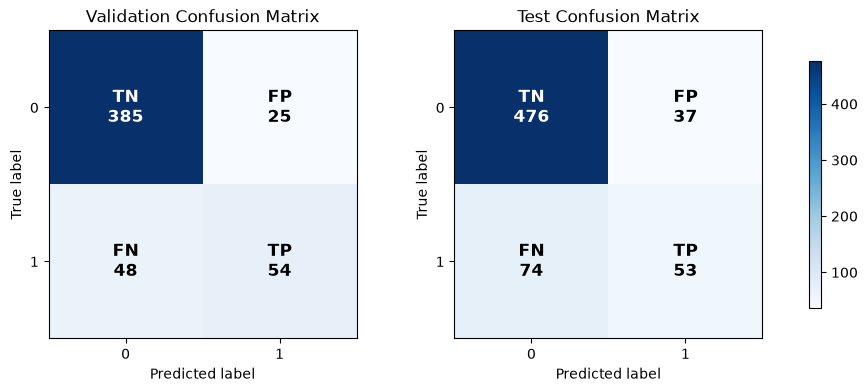

In [19]:
# 혼동 행렬 - Validation / Test 좌우 비교
def plot_confusion_matrices(y_valid_true, y_valid_pred,
                            y_test_true, y_test_pred):

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    datasets = [
        ("Validation Confusion Matrix", y_valid_true, y_valid_pred),
        ("Test Confusion Matrix", y_test_true, y_test_pred)
    ]

    # 이진 분류 혼동행렬 위치
    names = np.array([
        ["TN", "FP"],
        ["FN", "TP"]
    ])

    for ax, (title, y_true, y_pred) in zip(axes, datasets):

        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

        im = ax.imshow(
            cm,
            interpolation='nearest',
            cmap=plt.cm.Blues
        )

        ax.set_title(title)

        # 축 라벨
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["0", "1"])

        ax.set_yticks([0, 1])
        ax.set_yticklabels(["0", "1"])

        ax.set_ylabel("True label")
        ax.set_xlabel("Predicted label")

        # 셀 내부에 TN / FP / FN / TP + 개수 표시
        thresh = cm.max() / 2.

        for i, j in np.ndindex(cm.shape):

            text = f"{names[i, j]}\n{cm[i, j]}"

            ax.text(
                j, i,
                text,
                horizontalalignment="center",
                verticalalignment="center",
                fontsize=12,
                fontweight="bold",
                color="white" if cm[i, j] > thresh else "black"
            )

    fig.colorbar(im, ax=axes, shrink=0.8)

    plt.show()


plot_confusion_matrices(
    y_valid_true,
    y_valid_pred,
    y_test_true,
    y_test_pred
)

In [23]:
def print_metrics(name, y_true, y_pred, y_proba=None):
    print(f"=== {name} Metrics ===")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))
    if y_proba is not None:
        from sklearn.metrics import roc_auc_score
        print("ROC AUC Score:", roc_auc_score(y_true, y_proba))
    
    print("\n해석")
    print("- Accuracy: 모델이 얼마나 정확하게 예측했는지를 나타냅니다.")
    print("- Precision: 1 로 예측한 샘플 중에서 실제로 1 인 비율입니다.")
    print("- Recall: 실제 1 샘플 중에서 모델이 얼마나 잘 예측했는지를 나타냅니다.")
    print("- F1 Score: Precision과 Recall의 조화 평균입니다.")
    if y_proba is not None:
        print("- ROC AUC Score: 모델의 분류 성능을 나타내는 지표로, 1에 가까울수록 좋습니다.")
    print(classification_report(y_true, y_pred))


print_metrics("Validation", y_valid_true, y_valid_pred, valid_praba)
print_metrics("Test", y_test_true, y_test_pred, test_proba)

=== Validation Metrics ===
Accuracy: 0.857421875
Precision: 0.6835443037974683
Recall: 0.5294117647058824
F1 Score: 0.5966850828729282
ROC AUC Score: 0.8981348637015782

해석
- Accuracy: 모델이 얼마나 정확하게 예측했는지를 나타냅니다.
- Precision: 1 로 예측한 샘플 중에서 실제로 1 인 비율입니다.
- Recall: 실제 1 샘플 중에서 모델이 얼마나 잘 예측했는지를 나타냅니다.
- F1 Score: Precision과 Recall의 조화 평균입니다.
- ROC AUC Score: 모델의 분류 성능을 나타내는 지표로, 1에 가까울수록 좋습니다.
              precision    recall  f1-score   support

           0       0.89      0.94      0.91       410
           1       0.68      0.53      0.60       102

    accuracy                           0.86       512
   macro avg       0.79      0.73      0.76       512
weighted avg       0.85      0.86      0.85       512

=== Test Metrics ===
Accuracy: 0.8265625
Precision: 0.5888888888888889
Recall: 0.41732283464566927
F1 Score: 0.48847926267281105
ROC AUC Score: 0.8379303464259948

해석
- Accuracy: 모델이 얼마나 정확하게 예측했는지를 나타냅니다.
- Precision: 1 로 예측한 샘플 중에서 실제로 1 인 비율입니다.
- Recall: 실제 1 샘플 중에서 모델이 얼마나

In [25]:
def proba_summary(name, proba):
    if proba is None:
        print(f"{name} - No probability predictions available.")
        return

    print(f"=== {name} Probability Summary ===")
    print (pd.Series(proba).describe(percentiles=[.1,.25, .5, .75, .9]).round(4))

proba_summary("Validation", valid_praba)
proba_summary("Test", test_proba)

=== Validation Probability Summary ===
count    512.0000
mean       0.2179
std        0.2508
min        0.0022
10%        0.0146
25%        0.0379
50%        0.1018
75%        0.3154
90%        0.6300
max        0.9998
Name: pred_proba, dtype: float64
=== Test Probability Summary ===
count    640.0000
mean       0.2040
std        0.2464
min        0.0034
10%        0.0129
25%        0.0317
50%        0.0894
75%        0.2987
90%        0.5995
max        0.9970
Name: pred_proba, dtype: float64


In [29]:
# GridSearchCV를 사용하여 Logistic Regression 모델의 하이퍼파라미터 튜닝

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
import joblib


base_model = LogisticRegression(max_iter=3000)

param_grid = [{
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],    
    "solver": ['lbfgs']
},
{
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1'],
    "solver": ['liblinear']  # l1 penalty는 liblinear에서만 지원
}]

# 5개로 나누고 1 비율을 비슷하게
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # 5-fold cross-validation
grid = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring='f1',  # f1 score를 기준으로 최적 모델 선택
    cv=cv,
    n_jobs=-1,  # 모든 CPU 코어 사용
    verbose=1
)

grid.fit(X_train, y_train)

print("Best parameters found: ", grid.best_params_)
print("Best F1 score: ", grid.best_score_)

best_model = grid.best_estimator_

joblib.dump(best_model, "logreg_best_model.joblib")
print("\nBest model saved to logreg_best_model.joblib")

def make_pred_file(df_original, X, model, out_csv):
    # 예측 확률과 라벨 생성
    proba = model.predict_proba(X)[:, 1]
    pred_label = (proba >= 0.5).astype(int)

    # 원본 데이터에 예측 결과 추가
    df_result = df_original.copy()
    df_result["pred_proba"] = proba
    df_result["pred_label"] = pred_label

    # 결과를 CSV 파일로 저장
    df_result.to_csv(out_csv, index=False)
    print(f"Predictions saved to {out_csv}")

make_pred_file(valid_final, X_valid, best_model, "pred_valid_best_model.csv")
make_pred_file(test_final, X_test, best_model, "pred_test_best_model.csv")

print("\n작업 완료: 최적 파라미터 탐색 + 모델 저장 + 예측 파일 저장")
    

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters found:  {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
Best F1 score:  0.5080802000569442

Best model saved to logreg_best_model.joblib
Predictions saved to pred_valid_best_model.csv
Predictions saved to pred_test_best_model.csv

작업 완료: 최적 파라미터 탐색 + 모델 저장 + 예측 파일 저장


c:\Users\AJW\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\AJW\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [34]:
# 파라미터 튜닝 후 모델 평가
BEST_VALID_PATH = "pred_valid_best_model.csv"
BEST_TEST_PATH = "pred_test_best_model.csv"

BASE_VALID_PATH = "pred_valid_logreg.csv"
BASE_TEST_PATH = "pred_test_logreg.csv"

base_valid = pd.read_csv(BASE_VALID_PATH)
base_test = pd.read_csv(BASE_TEST_PATH)

best_valid = pd.read_csv(BEST_VALID_PATH)
best_test = pd.read_csv(BEST_TEST_PATH)

print("로드 완료")
print(f"base_valid: {base_valid.shape}, base_test: {base_test.shape}")
print(f"best_valid: {best_valid.shape}, best_test: {best_test.shape}")

def check_cols(df, name):
    need = [TARGET, "pred_label"]
    for col in need:
        if col not in df.columns:
            raise ValueError(f"{name}에 {col} 컬럼이 없습니다.")
    if "pred_proba" not in df.columns:
        print(f"{name}에 pred_proba 컬럼이 없습니다. 확률 예측은 불가합니다.")

check_cols(base_valid, "base_valid")
check_cols(base_test, "base_test")
check_cols(best_valid, "best_valid")
check_cols(best_test, "best_test")

def confusion_table(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return pd.DataFrame(
        cm,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )

def calc_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return pd.DataFrame({
        "Accuracy": [accuracy],
        "Precision": [precision],
        "Recall": [recall],
        "F1 Score": [f1]
    })

def compare_one_split(split_name, base_df, best_df):
    print(f"=== {split_name} Comparison ===")

    y_true_base = base_df[TARGET]
    y_pred_base = base_df["pred_label"]

    y_true_best = best_df[TARGET]
    y_pred_best = best_df["pred_label"]

    # 데이터 개수 확인
    if len(y_true_base) != len(y_true_best):
        raise ValueError(
            f"{split_name} 데이터 개수가 다릅니다. "
            f"baseline={len(y_true_base)}, best={len(y_true_best)}"
        )

    # 실제 정답이 같은지 확인
    if not np.array_equal(y_true_base.values, y_true_best.values):
        diff_count = np.sum(
            y_true_base.values != y_true_best.values
        )

        raise ValueError(
            f"{split_name}의 타깃 값이 일치하지 않습니다. "
            f"불일치 개수: {diff_count}"
        )

    # -----------------------------
    # Confusion Matrix
    # -----------------------------
    print("\nBaseline Confusion Matrix:")
    display(
        confusion_table(
            y_true_base,
            y_pred_base
        )
    )

    print("\nBest Confusion Matrix:")
    display(
        confusion_table(
            y_true_best,
            y_pred_best
        )
    )

    # -----------------------------
    # Metrics
    # -----------------------------
    m_base = calc_metrics(
        y_true_base,
        y_pred_base
    )

    m_best = calc_metrics(
        y_true_best,
        y_pred_best
    )

    print("\nBaseline Metrics:")
    print(
        f"Accuracy : {m_base['Accuracy'].iloc[0]:.4f}\n"
        f"Precision: {m_base['Precision'].iloc[0]:.4f}\n"
        f"Recall   : {m_base['Recall'].iloc[0]:.4f}\n"
        f"F1 Score : {m_base['F1 Score'].iloc[0]:.4f}"
    )

    print("\nBest Metrics:")
    print(
        f"Accuracy : {m_best['Accuracy'].iloc[0]:.4f}\n"
        f"Precision: {m_best['Precision'].iloc[0]:.4f}\n"
        f"Recall   : {m_best['Recall'].iloc[0]:.4f}\n"
        f"F1 Score : {m_best['F1 Score'].iloc[0]:.4f}"
    )

    # -----------------------------
    # 비교표
    # -----------------------------
    base_values = m_base.iloc[0]
    best_values = m_best.iloc[0]

    compare_df = pd.DataFrame(
        [
            base_values,
            best_values,
            best_values - base_values
        ],
        index=[
            "Baseline",
            "Best",
            "Difference (Best - Base)"
        ]
    )

    print("\n요약 비교표")
    display(compare_df.round(4))

    return compare_df

valid_compare = compare_one_split("VALID", base_valid, best_valid)
test_compare = compare_one_split("TEST", base_test, best_test)

valid_compare.to_csv("compare_valid_baseline_vs_best.csv", index=True)
test_compare.to_csv("compare_test_baseline_vs_best.csv", index=True)

print("\n비교표 저장 완료: compare_valid_baseline_vs_best.csv, compare_test_baseline_vs_best.csv")


로드 완료
base_valid: (512, 267), base_test: (640, 267)
best_valid: (512, 267), best_test: (640, 267)
=== VALID Comparison ===

Baseline Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,385,25
Actual 1,48,54



Best Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,383,27
Actual 1,50,52



Baseline Metrics:
Accuracy : 0.8574
Precision: 0.6835
Recall   : 0.5294
F1 Score : 0.5967

Best Metrics:
Accuracy : 0.8496
Precision: 0.6582
Recall   : 0.5098
F1 Score : 0.5746

요약 비교표


,Accuracy,Precision,Recall,F1 Score
Baseline,0.8574,0.6835,0.5294,0.5967
Best,0.8496,0.6582,0.5098,0.5746
Difference (Best - Base),-0.0078,-0.0253,-0.0196,-0.0221


... (3 outputs left out)

,Predicted 0,Predicted 1
Actual 0,477,36
Actual 1,75,52



Baseline Metrics:
Accuracy : 0.8266
Precision: 0.5889
Recall   : 0.4173
F1 Score : 0.4885

Best Metrics:
Accuracy : 0.8266
Precision: 0.5909
Recall   : 0.4094
F1 Score : 0.4837

요약 비교표


,Accuracy,Precision,Recall,F1 Score
Baseline,0.8266,0.5889,0.4173,0.4885
Best,0.8266,0.5909,0.4094,0.4837
Difference (Best - Base),0.0000,0.0020,-0.0079,-0.0048



비교표 저장 완료: compare_valid_baseline_vs_best.csv, compare_test_baseline_vs_best.csv
